<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo desta aula e LAB explorar os modelos de Stacking, Baggin e Boosting.**

Inteligência Artificial - ML com Scikit-learn

**Alunos (dupla):** Pedro Gabriel Takenobu Serafim e Rubens Rodrigues Maranesi

## Ensemble Models

Os métodos de Ensemble (conjuntos) combinam as previsões de vários estimadores base para melhorar a capacidade de generalização e a robustez do modelo em comparação a um único estimador.
Abaixo estão os pontos centrais e os principais tipos de ensembles disponíveis no scikit-learn:
- Exemplos Clássicos: As árvores com gradient-boosting (como o Gradient Boosting Classifier/Regressor) e as florestas aleatórias (Random Forests) são dois dos exemplos mais famosos e utilizados.
- Flexibilidade: Embora modelos baseados em árvores de decisão sejam muito comuns, os métodos de ensemble podem ser aplicados a qualquer outro algoritmo de aprendizado (como regressão logística, SVM ou redes neurais).

Principais Categorias de Ensembles

- Métodos de Média (Averaging / Bagging): Treinam vários estimadores de forma independente e depois calculam a média de suas previsões (ou votação). O foco principal é reduzir a variância do modelo. Exemplos: Bagging e Random Forests.
- Métodos de Impulsionamento (Boosting): Treinam estimadores de forma sequencial, onde cada novo modelo tenta corrigir os erros cometidos pelos anteriores. O foco principal é reduzir o viés do modelo. Exemplos: AdaBoost e Gradient Boosting.
- Votação e Empilhamento (Voting & Stacking): O Voting combina a previsão de modelos heterogêneos por voto majoritário ou média ponderada. O Stacking (como visto anteriormente) usa um classificador final para aprender a combinar o output dos modelos base de forma otimizada.


[Scikit-Learn]

- https://scikit-learn.org/stable/modules/ensemble.html

## Bagging

No contexto do **Scikit-Learn**, os modelos de **Bagging** (como o `BaggingClassifier` e `BaggingRegressor`, além do clássico `RandomForestClassifier`) funcionam criando um comitê (*ensemble*) de estimadores base, geralmente árvores de decisão, treinados de forma paralela e independente em diferentes subconjuntos aleatórios dos dados de treino gerados por amostragem com reposição (método conhecido como *bootstrapping*). Ao final, o modelo combina as previsões individuais de cada estimador — por meio de votação majoritária para classificação ou média aritmética para regressão — reduzindo significativamente a variância do modelo final e ajudando a evitar o problema de sobreajuste (*overfitting*) sem aumentar o viés.

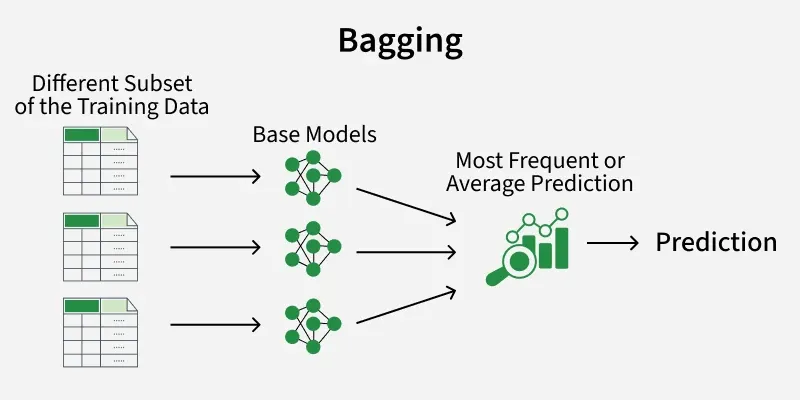

https://www.geeksforgeeks.org/machine-learning/bagging-vs-boosting-vs-stacking/

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html

## Boosting

Diferente do Bagging, os modelos de **Boosting** (como o `AdaBoostClassifier`, `GradientBoostingClassifier` ou o moderno `HistGradientBoostingClassifier` no **Scikit-Learn**) funcionam de forma sequencial, onde cada novo estimador é treinado para corrigir especificamente os erros cometidos pelos estimadores anteriores. Em vez de independência, há uma dependência direta: o algoritmo ajusta os pesos das instâncias mal classificadas (no caso do AdaBoost) ou otimiza os resíduos da função de perda (no caso do Gradient Boosting) a cada iteração. No final, as previsões são combinadas por meio de uma média ponderada pelo desempenho de cada modelo, focando fortemente na redução do viés e na criação de um preditor final altamente robusto a partir de classificadores fracos (*weak learners*).

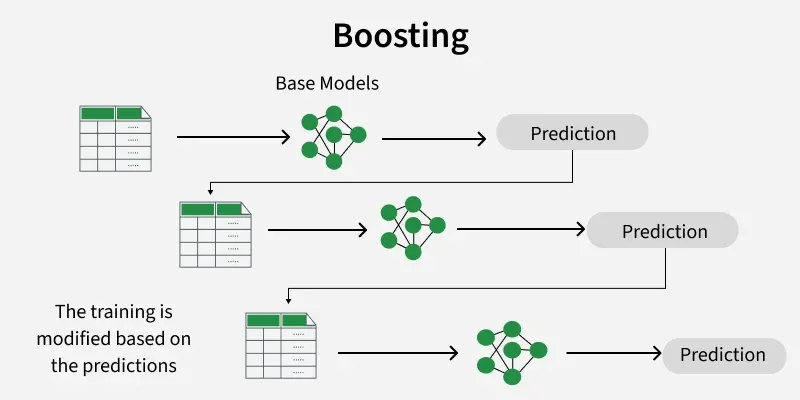

https://www.geeksforgeeks.org/machine-learning/boosting-in-machine-learning/

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html

## Stacking

Stacking: Combinando modelos diferentes:

O Stacking (generalização empilhada) consiste em combinar as previsões de múltiplos modelos de machine learning (estimadores base) usando um classificador final para tomar a decisão. Essa técnica permite aproveitar os pontos fortes de cada modelo individual, transformando os resultados deles em novas entradas (features) para o estimador final.

Aqui estão os pontos centrais sobre o funcionamento dessa estratégia:

- Treinamento em duas etapas: Os estimadores base são treinados com o conjunto de dados completo (\(X\)). Já o estimador final é treinado usando as previsões dos estimadores base obtidas via validação cruzada (cross_val_predict), o que evita o sobreajuste (overfitting).
- Flexibilidade de problemas: A biblioteca scikit-learn oferece suporte para essa estratégia tanto em problemas de classificação (StackingClassifier) quanto de regressão (StackingRegressor).
- Configuração em paralelo: O parâmetro estimators recebe uma lista composta por nomes e seus respectivos modelos, configurando-os para processar os dados de entrada de forma paralela antes de enviar os resultados para a etapa final.



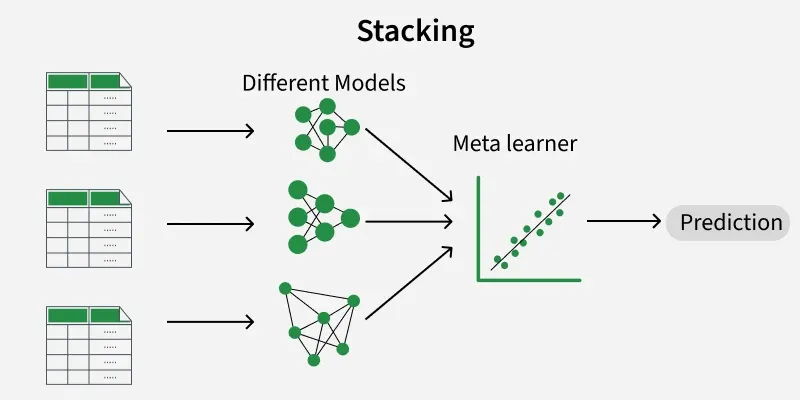

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html

https://scikit-learn.org/stable/modules/ensemble.html#stacking

## LAB
- Ler material do Geeks for Geeks (links)
- Para entrega (LAB semanal)
- Em duplas (pairing)
- Implementar um modelo de Boosting
- Implementar um modelo de Bagging
- Ou implementar um modelo de Stacking (Implementar 2 modelos ou 3)
- Usar dados do vega dataset (cada grupo usa um conjunto de dados diferente)
- Implementar com Scikit-Learn
- Publicar projeto no GitHub .ipynb
- Postar link da ativdade do MS Teams
- Citar o nome dos alunos

## Exemplo

Código em Python de exemplo prático: Stacking com o Dataset `cars` do Vega usando LIB de IA ML Scikit-Learn

In [ ]:
# IA LLM Google Gemini 3.5 Flash
# Estudar o código e perceber o workflow (fuxo) do Scikit-Learn para IA ML

import pandas as pd
import numpy as np
from vega_datasets import data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Carregar os dados de carros do vega_datasets
df = data.cars()
print("Dimensões do dataset original:", df.shape)

# 2. Pré-processamento dos dados
# Vamos definir nossa variável alvo (target): prever se o carro é dos EUA (USA) ou Outro (Europe/Japan)
df['Is_USA'] = (df['Origin'] == 'USA').astype(int)

# Selecionar variáveis numéricas preditoras
features = ['Miles_per_Gallon', 'Cylinders', 'Displacement', 'Horsepower', 'Weight_in_lbs', 'Acceleration']
X = df[features]
y = df['Is_USA']

# 3. Divisão entre treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 4. Criação dos estimadores base (Base Learners)
# Adicionando a Rede Neural Artificial (MLPClassifier) aos estimadores com max_iter=1000 para evitar avisos de convergência
base_estimators = [
    ('rf', make_pipeline(SimpleImputer(strategy='median'),
                        RandomForestClassifier(n_estimators=100, random_state=42))),
    ('svm', make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler(), SVC(probability=True, random_state=42))),
    ('rna', make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler(), MLPClassifier(hidden_layer_sizes=(50, 25), max_iter=1000, random_state=42)))
]

# 5. Definição do Classificador Final (Meta-Learner)
final_estimator = LogisticRegression()

# 6. Construindo o Stacking Classifier
stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=final_estimator,
    cv=5
)

# 7. Treinando o modelo
stacking_model.fit(X_train, y_train)

# 8. Avaliação do modelo nos dados de teste
y_pred = stacking_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nAcurácia do Modelo Stacking (com RNA): {accuracy:.4f}\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=['Outro', 'EUA']))

Dimensões do dataset original: (406, 9)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(



Acurácia do Modelo Stacking (com RNA): 0.9020

Relatório de Classificação:
              precision    recall  f1-score   support

       Outro       0.85      0.89      0.87        38
         EUA       0.94      0.91      0.92        64

    accuracy                           0.90       102
   macro avg       0.89      0.90      0.90       102
weighted avg       0.90      0.90      0.90       102



## Implementação do LAB: Bagging e Boosting com o dataset `cars`

**Alunos (dupla):** Pedro Gabriel Takenobu Serafim e Rubens Rodrigues Maranesi

**Dataset:** `cars` (vega_datasets)

**Objetivo:** prever se um carro é dos **EUA** ou de **outra origem** (Europa/Japão) a partir de suas características técnicas, comparando um modelo único (baseline) com modelos de **Bagging** e **Boosting**.

_O exemplo de Stacking acima foi mantido; a seguir está a implementação do LAB._

### 1. Importação das bibliotecas

In [1]:
# !pip install vega_datasets  # descomente se estiver rodando fora do Colab

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vega_datasets import data

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier,
    AdaBoostClassifier, GradientBoostingClassifier,
)
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42

### 2. Carregando e explorando os dados

In [2]:
df = data.cars()
print("Dimensões:", df.shape)
df.head()

Dimensões: (406, 9)


,Name,Miles_per_Gallon,Cylinders,Displacement,Horsepower,Weight_in_lbs,Acceleration,Year,Origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,1970-01-01,USA
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,1970-01-01,USA
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,1970-01-01,USA
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,1970-01-01,USA
4,ford torino,17.0,8,302.0,140.0,3449,10.5,1970-01-01,USA


In [3]:
print("Valores ausentes por coluna:")
print(df.isna().sum())
print("\nDistribuição da origem:")
print(df["Origin"].value_counts())

Valores ausentes por coluna:
Name                0
Miles_per_Gallon    8
Cylinders           0
Displacement        0
Horsepower          6
Weight_in_lbs       0
Acceleration        0
Year                0
Origin              0
dtype: int64

Distribuição da origem:
Origin
USA       254
Japan      79
Europe     73
Name: count, dtype: int64


### 3. Pré-processamento

- **Alvo (`Is_USA`):** 1 se o carro é dos EUA, 0 caso contrário.
- **Variáveis preditoras:** as 6 variáveis numéricas do dataset.
- As colunas `Miles_per_Gallon` e `Horsepower` têm valores ausentes, que serão preenchidos com a **mediana** dentro de cada `pipeline`. Assim a mediana é calculada só com os dados de treino, o que evita *data leakage*.
- Divisão **75% treino / 25% teste**, estratificada pela classe.

In [4]:
df["Is_USA"] = (df["Origin"] == "USA").astype(int)

features = ["Miles_per_Gallon", "Cylinders", "Displacement",
            "Horsepower", "Weight_in_lbs", "Acceleration"]
X = df[features]
y = df["Is_USA"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Proporção EUA no treino: %.2f | no teste: %.2f" % (y_train.mean(), y_test.mean()))

Treino: (304, 6) | Teste: (102, 6)
Proporção EUA no treino: 0.62 | no teste: 0.63


### 4. Modelo base (baseline): Árvore de Decisão

Um único estimador, usado como referência para medir o ganho dos ensembles.

In [5]:
modelos = {}

modelos["Árvore de Decisão (baseline)"] = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(random_state=RANDOM_STATE),
)

### 5. Bagging

O **Bagging** treina vários estimadores **em paralelo e de forma independente**, cada um em uma amostra *bootstrap* (com reposição) dos dados de treino. A previsão final é a **votação majoritária**. O principal efeito é **reduzir a variância**.

Usaremos:
- `BaggingClassifier` com árvores de decisão como estimador base;
- `RandomForestClassifier`, um Bagging de árvores que também sorteia um subconjunto de variáveis em cada divisão.

In [6]:
modelos["Bagging (árvores)"] = make_pipeline(
    SimpleImputer(strategy="median"),
    BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        max_samples=1.0,      # cada árvore vê uma amostra bootstrap do tamanho do treino
        bootstrap=True,
        oob_score=True,       # avaliação "out-of-bag" gratuita
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
)

modelos["Random Forest"] = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
)

### 6. Boosting

O **Boosting** treina estimadores **em sequência**, e cada novo modelo tenta corrigir os erros dos anteriores. O principal efeito é **reduzir o viés**.

Usaremos:
- `AdaBoostClassifier`, que aumenta o peso das instâncias mal classificadas;
- `GradientBoostingClassifier`, que ajusta cada nova árvore aos resíduos (gradiente da função de perda).

In [7]:
modelos["AdaBoost"] = make_pipeline(
    SimpleImputer(strategy="median"),
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2),
        n_estimators=200,
        learning_rate=0.5,
        random_state=RANDOM_STATE,
    ),
)

modelos["Gradient Boosting"] = make_pipeline(
    SimpleImputer(strategy="median"),
    GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        random_state=RANDOM_STATE,
    ),
)

### 7. Treinamento e avaliação no conjunto de teste

In [8]:
resultados_teste = {}

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    resultados_teste[nome] = accuracy_score(y_test, y_pred)

tab_teste = (pd.Series(resultados_teste, name="Acurácia (teste)")
             .sort_values(ascending=False).to_frame())
tab_teste.style.format("{:.4f}")

,Acurácia (teste)
Bagging (árvores),0.9510
Gradient Boosting,0.9118
AdaBoost,0.9118
Árvore de Decisão (baseline),0.9020
Random Forest,0.9020


In [9]:
# Acurácia out-of-bag do Bagging (estimada só com os dados de treino)
oob = modelos["Bagging (árvores)"].named_steps["baggingclassifier"].oob_score_
print(f"Acurácia OOB do Bagging: {oob:.4f}")

Acurácia OOB do Bagging: 0.8980


### 8. Validação cruzada repetida

Com apenas 102 amostras no teste, a diferença de 1 ou 2 carros muda a acurácia em cerca de 1 ponto percentual. Para uma comparação mais confiável, usamos **validação cruzada estratificada 5-fold repetida 5 vezes** (25 avaliações por modelo) em todo o dataset.

In [10]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

linhas = []
scores_por_modelo = {}
for nome, modelo in modelos.items():
    scores = cross_val_score(modelo, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    scores_por_modelo[nome] = scores
    linhas.append({"Modelo": nome, "Média": scores.mean(), "Desvio padrão": scores.std()})

tab_cv = pd.DataFrame(linhas).sort_values("Média", ascending=False).reset_index(drop=True)
tab_cv.style.format({"Média": "{:.4f}", "Desvio padrão": "{:.4f}"})

,Modelo,Média,Desvio padrão
0,Bagging (árvores),0.9192,0.0257
1,Gradient Boosting,0.9108,0.0269
2,AdaBoost,0.9044,0.0227
3,Random Forest,0.9034,0.0270
4,Árvore de Decisão (baseline),0.8897,0.0348


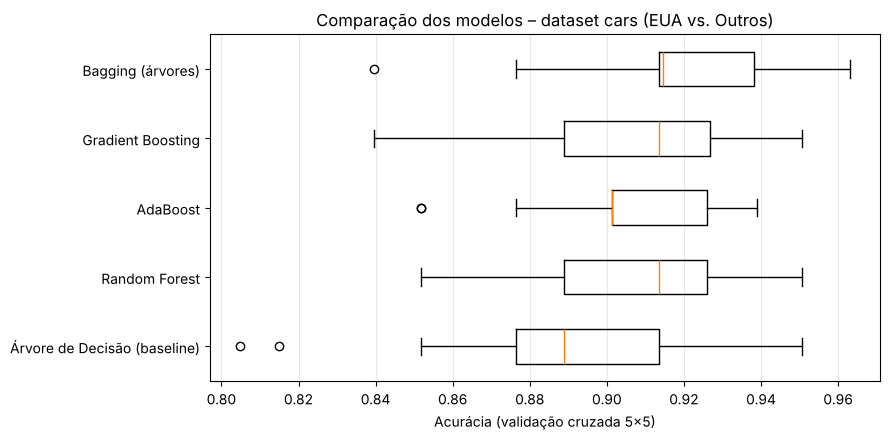

In [11]:
ordem = tab_cv["Modelo"].tolist()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([scores_por_modelo[n] for n in ordem], vert=False)
ax.set_yticklabels(ordem)
ax.invert_yaxis()
ax.set_xlabel("Acurácia (validação cruzada 5x5)")
ax.set_title("Comparação dos modelos – dataset cars (EUA vs. Outros)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 9. Análise detalhada do melhor modelo

Melhor modelo (validação cruzada): Bagging (árvores)

              precision    recall  f1-score   support

       Outro       0.95      0.92      0.93        38
         EUA       0.95      0.97      0.96        64

    accuracy                           0.95       102
   macro avg       0.95      0.94      0.95       102
weighted avg       0.95      0.95      0.95       102



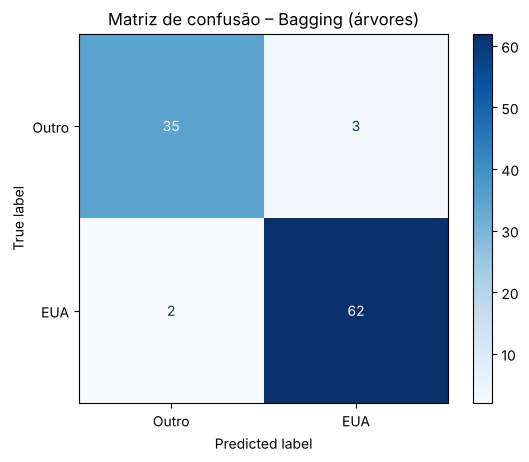

In [12]:
melhor_nome = tab_cv.loc[0, "Modelo"]
melhor = modelos[melhor_nome]
y_pred = melhor.predict(X_test)

print(f"Melhor modelo (validação cruzada): {melhor_nome}\n")
print(classification_report(y_test, y_pred, target_names=["Outro", "EUA"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Outro", "EUA"], cmap="Blues"
)
plt.title(f"Matriz de confusão – {melhor_nome}")
plt.show()

### Importância das variáveis

Os ensembles baseados em árvores permitem medir quanto cada variável contribuiu para as decisões.

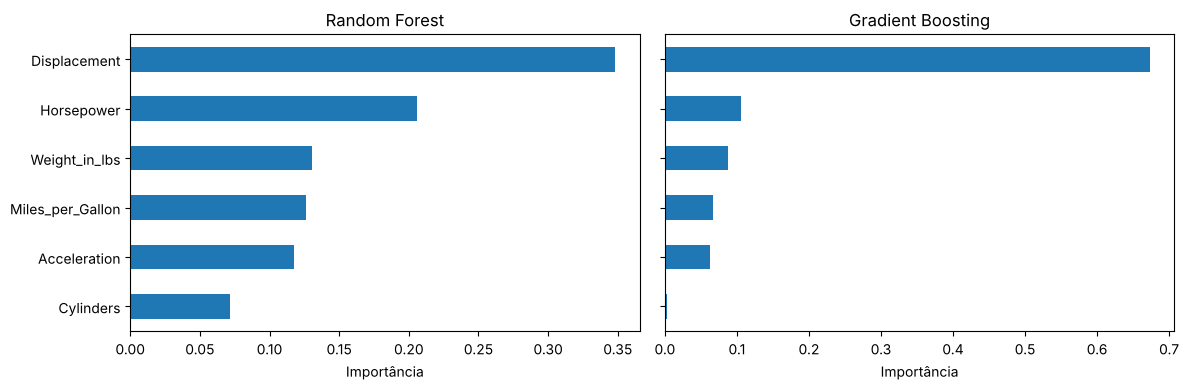

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, nome, step in [
    (axes[0], "Random Forest", "randomforestclassifier"),
    (axes[1], "Gradient Boosting", "gradientboostingclassifier"),
]:
    imp = pd.Series(modelos[nome].named_steps[step].feature_importances_, index=features)
    imp.sort_values().plot.barh(ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Importância")
plt.tight_layout()
plt.show()

### 10. Conclusões

**Resultados (validação cruzada 5x5, acurácia média ± desvio padrão):**

| Modelo | Tipo | Acurácia |
|---|---|---|
| Bagging (árvores) | Bagging | 0,919 ± 0,026 |
| Gradient Boosting | Boosting | 0,911 ± 0,027 |
| AdaBoost | Boosting | 0,904 ± 0,023 |
| Random Forest | Bagging | 0,903 ± 0,027 |
| Árvore de Decisão | Baseline | 0,890 ± 0,035 |

**O que observamos**

1. **Todos os ensembles superaram o modelo único** (árvore de decisão) em média, e o desvio padrão caiu de 0,035 para cerca de 0,025. Isso é o efeito esperado da combinação de vários estimadores: modelos mais estáveis e que generalizam melhor.
2. **O Bagging de árvores foi o melhor.** No conjunto de teste ele chegou a 95,1% contra 90,2% do baseline, ou seja, 5 carros a mais classificados corretamente em 102. A acurácia *out-of-bag* (89,8%) ficou um pouco abaixo da do teste, o que indica que o resultado do teste foi um pouco otimista.
3. **A diferença entre os ensembles é pequena**, menor que o desvio padrão da validação cruzada. Com apenas 406 carros não dá para afirmar que um ensemble seja realmente melhor que outro, só que todos tendem a ser melhores que uma árvore isolada.
4. **Por que o Boosting não ganhou?** Uma possível explicação: o Boosting reduz o *viés*, e uma única árvore já separa razoavelmente bem as classes neste problema, então o maior ganho vem de reduzir a *variância*, que é justamente o que o Bagging faz. Com poucos dados, o Boosting também pode se ajustar ao ruído. Esta é uma hipótese; para confirmá-la seria preciso testar outros hiperparâmetros e outros datasets.
5. **Variáveis mais importantes:** a cilindrada (`Displacement`) foi a que mais pesou nos dois modelos, seguida de potência e peso; o número de cilindros teve a menor importância. Isso é coerente com o contexto da época, em que os carros americanos tinham motores maiores e mais potentes. Como cilindrada e cilindros são muito correlacionadas, a importância pode ter se concentrado em uma delas.

**Limitações e próximos passos:** o dataset é pequeno e levemente desbalanceado (62% EUA). Seria possível testar ajuste de hiperparâmetros (`GridSearchCV`), outros algoritmos de Boosting (`HistGradientBoostingClassifier`) e um *Stacking* combinando esses modelos.

## Avaliação

- Entregar todos os projetos mesmo atrasado
- Em duplas (pairing), verificar se o nome consta no projeto
- Só um aluno precisa entregar: .ipynb no GitHub, link do repo no MS Teams (Atividade)
- A média dos projetos de LAB semanais vão compor a nota final, média dos projetos

## Estudo

**Atenção**: Estudar os 3 primeiros capítulos do livro Artificial Intelligence: A Modern Approach: https://aima.cs.berkeley.edu/


## Infográficos

![](https://miro.medium.com/v2/resize:fit:1400/1*_0Vw9HE1vbhD4ZW3OZZaQQ.png)

https://medium.com/data-science-collective/bagging-vs-boosting-a-deep-dive-into-ensemble-learning-for-tree-based-models-b3a061da3e62

![](https://i0.wp.com/spotintelligence.com/wp-content/uploads/2024/03/bagging-boosting-stacking-1024x576.webp?resize=1024%2C576&ssl=1)

https://spotintelligence.com/2023/08/09/ensemble-learning/